In [44]:
import torch
import torchvision
from torchvision.transforms import v2
import matplotlib.pyplot as plt
import numpy as np
import torch.nn as nn
import torch.nn.functional as F
import math


# Dataset

In [45]:
transform = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])

batch_size = 128

trainset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size, shuffle=True, num_workers=2)

testset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size, shuffle=False, num_workers=2)

classes = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

Files already downloaded and verified
Files already downloaded and verified


In [46]:
print("Training images:", len(trainset))
print("Testing images:", len(testset))

Training images: 50000
Testing images: 10000


[[[0.5        0.5        0.5        ... 0.5        0.5        0.5       ]
  [0.5        0.5        0.5        ... 0.5        0.5        0.5       ]
  [0.5        0.5        0.27058825 ... 0.9607844  0.5        0.5       ]
  ...
  [0.5        0.5        0.3019608  ... 0.3921569  0.5        0.5       ]
  [0.5        0.5        0.5        ... 0.5        0.5        0.5       ]
  [0.5        0.5        0.5        ... 0.5        0.5        0.5       ]]

 [[0.5        0.5        0.5        ... 0.5        0.5        0.5       ]
  [0.5        0.5        0.5        ... 0.5        0.5        0.5       ]
  [0.5        0.5        0.2901961  ... 0.95294124 0.5        0.5       ]
  ...
  [0.5        0.5        0.2392157  ... 0.30980393 0.5        0.5       ]
  [0.5        0.5        0.5        ... 0.5        0.5        0.5       ]
  [0.5        0.5        0.5        ... 0.5        0.5        0.5       ]]

 [[0.5        0.5        0.5        ... 0.5        0.5        0.5       ]
  [0.5        0.5     

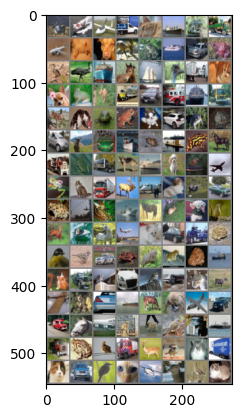

deer  ship  plane truck cat   ship  frog  truck plane dog   dog   deer  frog  ship  car   frog  bird  bird  ship  horse ship  bird  truck cat   dog   cat   deer  truck car   truck ship  truck horse cat   frog  frog  dog   car   frog  cat   car   deer  car   ship  frog  ship  frog  horse truck frog  truck dog   ship  dog   bird  plane frog  cat   truck deer  plane dog   deer  car   frog  plane deer  ship  horse deer  dog   bird  deer  ship  horse plane cat   car   truck frog  bird  bird  car   frog  frog  frog  cat   ship  cat   truck cat   car   bird  truck cat   deer  plane frog  car   ship  horse dog   plane car   truck horse plane cat   dog   bird  truck ship  truck frog  bird  truck deer  bird  cat   truck cat   car   bird  cat   plane deer  bird  cat  


In [47]:
def imshow(img):
    img = img / 2 + 0.5
    # normalize: 
    npimg = img.numpy()
    print(npimg)
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.show()
dataiter = iter(trainloader)
images, labels = next(dataiter)
imshow(torchvision.utils.make_grid(images))
print(' '.join(f'{classes[labels[j]]:5s}' for j in range(batch_size)))

# CNN Configuration

In [48]:
SEED = 42
EPOCHS = 20
LEARNING_RATE = 0.001

torch.manual_seed(SEED)
np.random.seed(SEED)

# CNN Model

In [49]:
class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 6, 5) # in_channel = 3; out_channel = 6; kernel_size = 5
        self.pool = nn.MaxPool2d(2, 2) # kernel_size = 2; stride = 2
        self.conv2 = nn.Conv2d(6, 16, 5)
        self.fc1 = nn.Linear(16 * 5 * 5, 120) # 120 is a hyperparameter
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = torch.flatten(x, 1) # flatten all dimensions except batch
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return x
net = Net()

# Define a Loss function and optimizer

In [50]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(net.parameters(), lr=LEARNING_RATE, momentum=0.9)

# Training & Analysis

## Training

In [51]:

# Configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = net.to(device)

# Information before training
print("Device:", device)
print("Batch size:", batch_size)
print("Learning rate:", LEARNING_RATE)

history = {
    "epoch": [],
    "train_loss": [],
    "test_loss": [],
    "train_accuracy": [],
    "test_accuracy": [],
    "learning_rate": [],
    "precision": [],
    "recall": [],
    "f1_score": []
}

# Training and Evaluation
for epoch in range(EPOCHS):

    # Training phase
    model.train()

    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for inputs, labels in trainloader:
        inputs = inputs.to(device)
        labels = labels.to(device)

        # Reset gradient
        optimizer.zero_grad()

        # Forward propagation
        outputs = model(inputs)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        # Accumulate statistics
        batch_size = labels.size(0)
        train_loss_sum += loss.item() * batch_size

        _, predicted = torch.max(outputs, dim=1)
        train_total += batch_size
        train_correct += (predicted == labels).sum().item()

    train_loss = train_loss_sum / train_total
    train_accuracy = 100.0 * train_correct / train_total

    # Testing phase
    model.eval()

    test_loss_sum = 0.0
    test_correct = 0
    test_total = 0

    with torch.no_grad():
        for inputs, labels in testloader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            # Forward propagation only
            outputs = model(inputs)

            # Calculate test loss
            loss = criterion(outputs, labels)

            batch_size = labels.size(0)
            test_loss_sum += loss.item() * batch_size

            _, predicted = torch.max(outputs, dim=1)
            test_total += batch_size
            test_correct += (predicted == labels).sum().item()

    test_loss = test_loss_sum / test_total
    test_accuracy = 100.0 * test_correct / test_total

    # Record metrics
    current_lr = optimizer.param_groups[0]["lr"]

    history["epoch"].append(epoch + 1)
    history["train_loss"].append(train_loss)
    history["test_loss"].append(test_loss)
    history["train_accuracy"].append(train_accuracy)
    history["test_accuracy"].append(test_accuracy)
    history["learning_rate"].append(current_lr)

    # Print results
    print(
        f"Epoch [{epoch + 1:02d}/{EPOCHS:02d}] | "
        f"LR: {current_lr:.6f} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Test Loss: {test_loss:.4f} | "
        f"Train Acc: {train_accuracy:.2f}% | "
        f"Test Acc: {test_accuracy:.2f}%"
    )


Device: cuda
Batch size: 128
Learning rate: 0.001
Epoch [01/20] | LR: 0.001000 | Train Loss: 2.3023 | Test Loss: 2.2987 | Train Acc: 12.40% | Test Acc: 15.83%
Epoch [02/20] | LR: 0.001000 | Train Loss: 2.2895 | Test Loss: 2.2708 | Train Acc: 16.08% | Test Acc: 17.20%
Epoch [03/20] | LR: 0.001000 | Train Loss: 2.1875 | Test Loss: 2.0792 | Train Acc: 19.40% | Test Acc: 23.83%
Epoch [04/20] | LR: 0.001000 | Train Loss: 1.9904 | Test Loss: 1.9056 | Train Acc: 28.56% | Test Acc: 32.11%
Epoch [05/20] | LR: 0.001000 | Train Loss: 1.8643 | Test Loss: 1.8132 | Train Acc: 32.40% | Test Acc: 34.78%
Epoch [06/20] | LR: 0.001000 | Train Loss: 1.7581 | Test Loss: 1.7058 | Train Acc: 36.20% | Test Acc: 37.99%
Epoch [07/20] | LR: 0.001000 | Train Loss: 1.6530 | Test Loss: 1.6096 | Train Acc: 39.72% | Test Acc: 41.15%
Epoch [08/20] | LR: 0.001000 | Train Loss: 1.5843 | Test Loss: 1.5531 | Train Acc: 42.09% | Test Acc: 43.25%
Epoch [09/20] | LR: 0.001000 | Train Loss: 1.5401 | Test Loss: 1.5106 | Train 

# Analysis

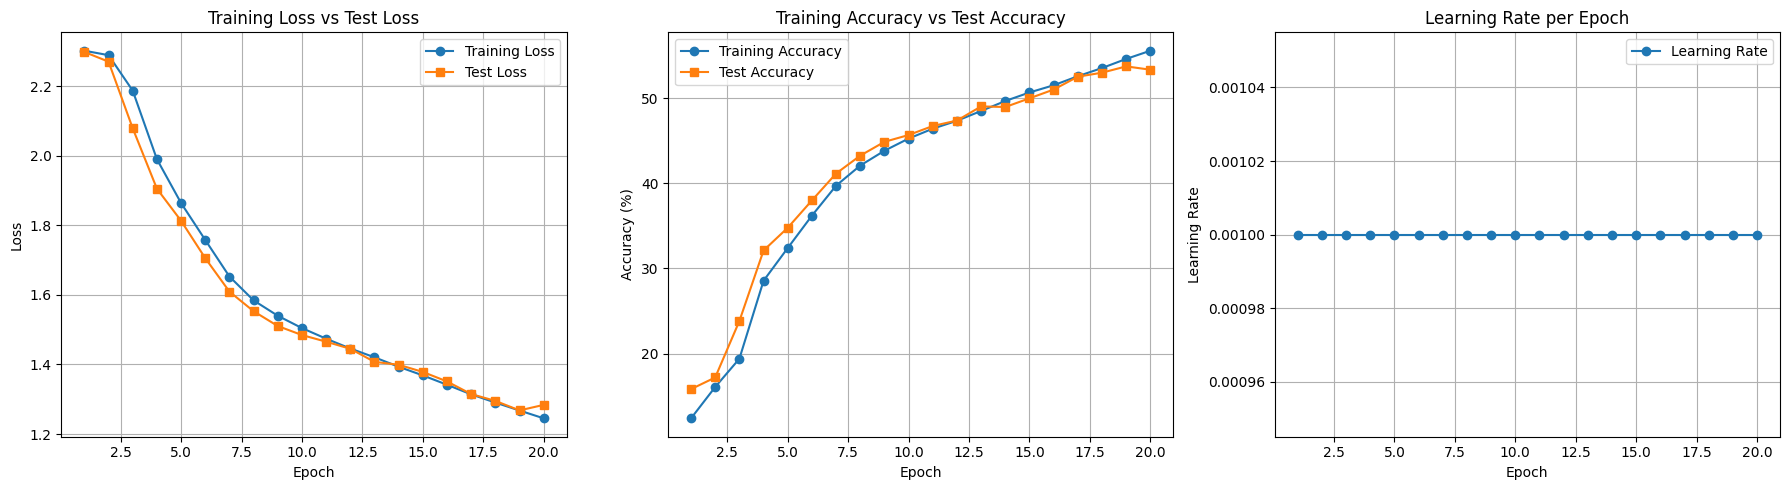

In [52]:
# Plot metrics
epochs = history["epoch"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Training Loss vs Test Loss
axes[0].plot(
    epochs, history["train_loss"],
    marker="o", label="Training Loss"
)
axes[0].plot(
    epochs, history["test_loss"],
    marker="s", label="Test Loss"
)
axes[0].set_title("Training Loss vs Test Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

# Plot 2: Training Accuracy vs Test Accuracy
axes[1].plot(
    epochs, history["train_accuracy"],
    marker="o", label="Training Accuracy"
)
axes[1].plot(
    epochs, history["test_accuracy"],
    marker="s", label="Test Accuracy"
)
axes[1].set_title("Training Accuracy vs Test Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()
axes[1].grid(True)

# Plot 3: Learning Rate
axes[2].plot(
    epochs, history["learning_rate"],
    marker="o", label="Learning Rate"
)
axes[2].set_title("Learning Rate per Epoch")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Learning Rate")
axes[2].legend()
axes[2].grid(True)

plt.tight_layout()
plt.show()

## Save Model

In [53]:
PATH = './cifar_net.pt'
torch.save(net.state_dict(), PATH)

# Testing

[[[0.5        0.5        0.5        ... 0.5        0.5        0.5       ]
  [0.5        0.5        0.5        ... 0.5        0.5        0.5       ]
  [0.5        0.5        0.61960787 ... 0.08235294 0.5        0.5       ]
  ...
  [0.5        0.5        0.45882356 ... 0.00392157 0.5        0.5       ]
  [0.5        0.5        0.5        ... 0.5        0.5        0.5       ]
  [0.5        0.5        0.5        ... 0.5        0.5        0.5       ]]

 [[0.5        0.5        0.5        ... 0.5        0.5        0.5       ]
  [0.5        0.5        0.5        ... 0.5        0.5        0.5       ]
  [0.5        0.5        0.43921572 ... 0.09803921 0.5        0.5       ]
  ...
  [0.5        0.5        0.45882356 ... 0.00392157 0.5        0.5       ]
  [0.5        0.5        0.5        ... 0.5        0.5        0.5       ]
  [0.5        0.5        0.5        ... 0.5        0.5        0.5       ]]

 [[0.5        0.5        0.5        ... 0.5        0.5        0.5       ]
  [0.5        0.5     

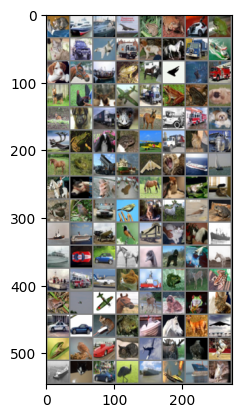

GroundTruth:  cat   ship  ship  plane frog  frog  car   frog  cat   car   plane truck dog   horse truck ship 


In [54]:
dataiter = iter(testloader)
images, labels = next(dataiter)

# print images
imshow(torchvision.utils.make_grid(images))
print('GroundTruth: ', ' '.join(f'{classes[labels[j]]:5s}' for j in range(batch_size)))

In [55]:
net = Net()
net.load_state_dict(torch.load(PATH, weights_only=True))

<All keys matched successfully>

In [56]:
outputs = net(images)

In [57]:
_, predicted = torch.max(outputs, 1)
print('Predicted: ', ' '.join(f'{classes[predicted[j]]:5s}'
                              for j in range(batch_size)))

Predicted:  cat   ship  ship  ship  frog  frog  car   frog  dog   car   plane truck frog  horse car   frog 


In [58]:
correct = 0
total = 0

with torch.no_grad():
    for data in testloader:
        images, labels = data
        # calculate outputs by running images through the network
        outputs = net(images)
        # the class with the highest energy is what we choose as prediction
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print(f'Accuracy of the network on the 10000 test images: {100 * correct // total} %')

Accuracy of the network on the 10000 test images: 53 %


In [59]:
# prepare to count predictions for each class
correct_pred = {classname: 0 for classname in classes}
total_pred = {classname: 0 for classname in classes}

# again no gradients needed
with torch.no_grad():
    for data in testloader:
        images, labels = data
        outputs = net(images)
        _, predictions = torch.max(outputs, 1)
        # collect the correct predictions for each class
        for label, prediction in zip(labels, predictions):
            if label == prediction:
                correct_pred[classes[label]] += 1
            total_pred[classes[label]] += 1


# print accuracy for each class
for classname, correct_count in correct_pred.items():
    accuracy = 100 * float(correct_count) / total_pred[classname]
    print(f'Accuracy for class: {classname:5s} is {accuracy:.1f} %')

Accuracy for class: plane is 72.2 %
Accuracy for class: car   is 78.5 %
Accuracy for class: bird  is 30.3 %
Accuracy for class: cat   is 20.6 %
Accuracy for class: deer  is 43.1 %
Accuracy for class: dog   is 49.6 %
Accuracy for class: frog  is 76.1 %
Accuracy for class: horse is 58.6 %
Accuracy for class: ship  is 67.2 %
Accuracy for class: truck is 37.2 %


# Confusion Matrix

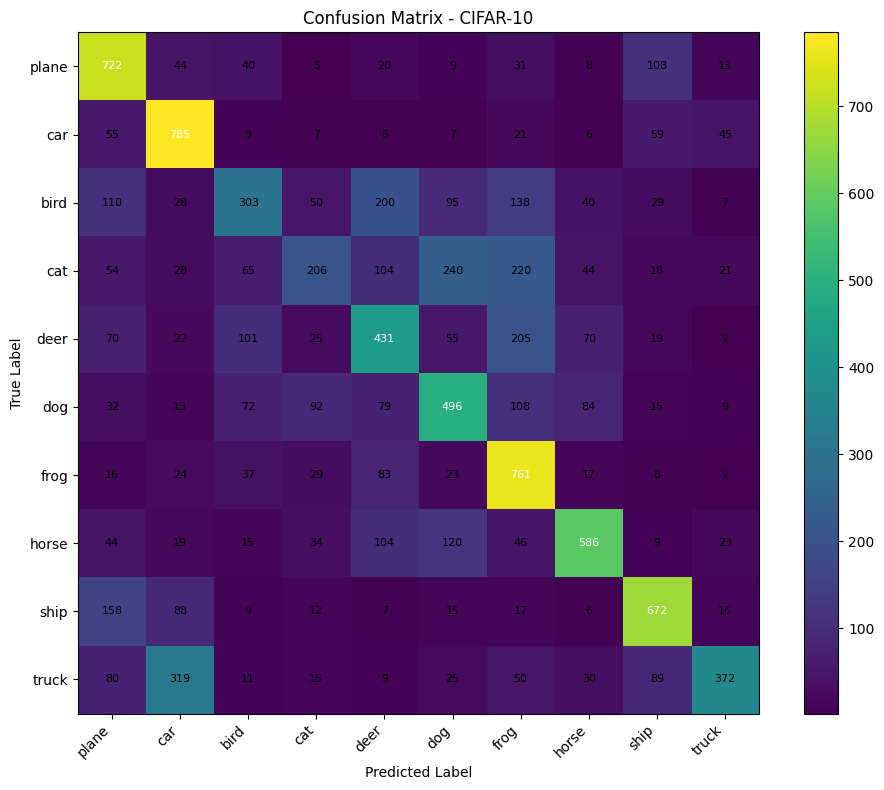

In [60]:
model.eval()

confusion_matrix = torch.zeros(
    10, 10, dtype=torch.int64
)

with torch.no_grad():
    for images, labels in testloader:
        images = images.to(device)
        labels = labels.to(device)

        logits = model(images)
        predictions = logits.argmax(dim=1)

        # Rows = true class; columns = predicted class
        indices = labels * 10 + predictions

        counts = torch.bincount(
            indices.cpu(), minlength=100
        ).reshape(10, 10)

        confusion_matrix += counts

cm = confusion_matrix.numpy()

fig, ax = plt.subplots(figsize=(10, 8))

im = ax.imshow(cm, interpolation="nearest")
ax.set_title("Confusion Matrix - CIFAR-10")
fig.colorbar(im, ax=ax)

ax.set_xticks(range(10))
ax.set_yticks(range(10))
ax.set_xticklabels(classes, rotation=45, ha="right")
ax.set_yticklabels(classes)

ax.set_xlabel("Predicted Label")
ax.set_ylabel("True Label")

threshold = cm.max() / 2

for i in range(10):
    for j in range(10):
        ax.text(
            j, i, str(cm[i, j]),
            ha="center", va="center",
            color="white" if cm[i, j] > threshold else "black",
            fontsize=8
        )

plt.tight_layout()
plt.show()

# Classification Metric

In [61]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x000002D9854A23E0>
Traceback (most recent call last):
  File "c:\toolbase\python\3.12.13.1\Lib\site-packages\torch\utils\data\dataloader.py", line 1604, in __del__
    self._shutdown_workers()
  File "c:\toolbase\python\3.12.13.1\Lib\site-packages\torch\utils\data\dataloader.py", line 1562, in _shutdown_workers
    if self._persistent_workers or self._workers_status[worker_id]:
                                   ^^^^^^^^^^^^^^^^^^^^
AttributeError: '_MultiProcessingDataLoaderIter' object has no attribute '_workers_status'


In [62]:
# ==========================================
# Classification Metrics on Test Set
# ==========================================
model.eval()

all_labels = []
all_predictions = []

with torch.no_grad():
    for inputs, labels in testloader:
        inputs = inputs.to(device)

        outputs = model(inputs)
        _, predicted = torch.max(outputs, dim=1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predicted.cpu().numpy())

# Calculate classification metrics
accuracy = accuracy_score(all_labels, all_predictions)

precision = precision_score(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

recall = recall_score(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

f1 = f1_score(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

print("\nClassification Metrics (Test Set)")
print(f"Accuracy : {accuracy * 100:.2f}%")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    all_labels,
    all_predictions,
    labels=list(range(10)),
    target_names=[
        "airplane", "automobile", "bird", "cat", "deer",
        "dog", "frog", "horse", "ship", "truck"
    ],
    zero_division=0
))


Classification Metrics (Test Set)
Accuracy : 53.34%
Precision: 0.5392
Recall   : 0.5334
F1-score : 0.5183

Classification Report:
              precision    recall  f1-score   support

    airplane       0.54      0.72      0.62      1000
  automobile       0.57      0.79      0.66      1000
        bird       0.46      0.30      0.36      1000
         cat       0.43      0.21      0.28      1000
        deer       0.41      0.43      0.42      1000
         dog       0.46      0.50      0.48      1000
        frog       0.48      0.76      0.59      1000
       horse       0.66      0.59      0.62      1000
        ship       0.65      0.67      0.66      1000
       truck       0.73      0.37      0.49      1000

    accuracy                           0.53     10000
   macro avg       0.54      0.53      0.52     10000
weighted avg       0.54      0.53      0.52     10000



# Display Misclassified Images

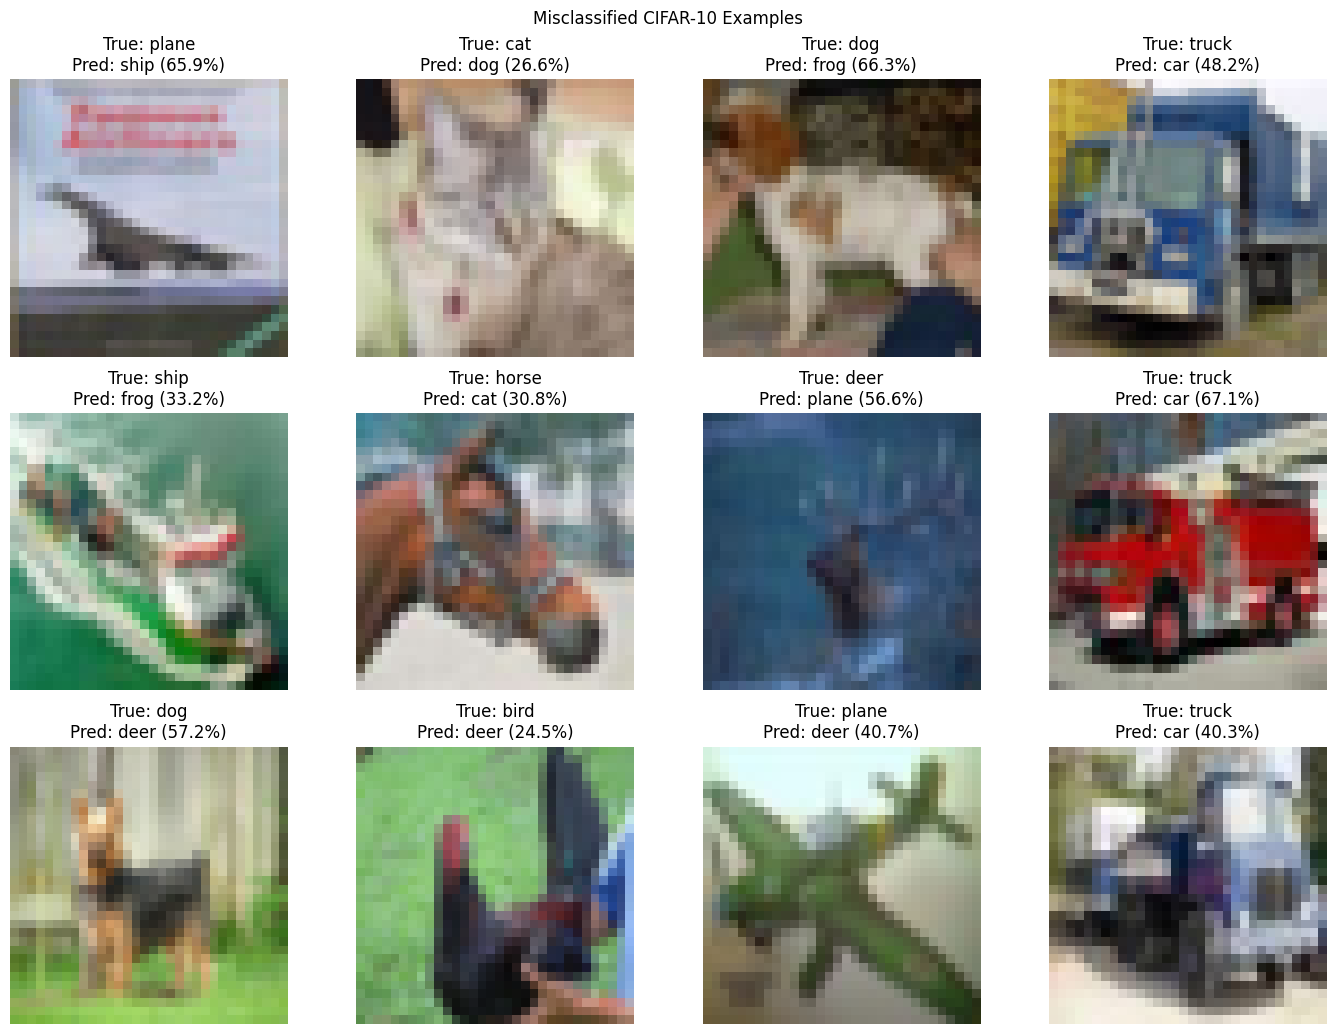


Final results
Train Loss: 1.2452
Test Loss:  1.2839
Train Acc:  55.57%
Test Acc:   53.34%
Number of test errors: 4666


In [66]:
model.eval()

wrong_images = []
wrong_labels = []
wrong_predictions = []
wrong_confidences = []

with torch.no_grad():
    for images, labels in testloader:
        images = images.to(device)
        labels = labels.to(device)

        logits = model(images)
        probabilities = torch.softmax(logits, dim=1)

        predictions = logits.argmax(dim=1)
        wrong_indices = (
            predictions != labels
        ).nonzero(as_tuple=True)[0]

        for idx in wrong_indices:
            wrong_images.append(
                images[idx].cpu()
            )
            wrong_labels.append(
                labels[idx].item()
            )
            wrong_predictions.append(
                predictions[idx].item()
            )
            wrong_confidences.append(
                probabilities[idx, predictions[idx]].item()
            )

            # Keep the first 12 errors
            if len(wrong_images) >= 12:
                break

        if len(wrong_images) >= 12:
            break

if len(wrong_images) == 0:
    print("No misclassified examples found.")
else:
    n = len(wrong_images)
    cols = 4
    rows = (n + cols - 1) // cols

    fig, axes = plt.subplots(
        rows, cols, figsize=(14, 3.5 * rows)
    )
    axes = np.asarray(axes).reshape(-1)

    for i in range(len(axes)):
        axes[i].axis("off")

    for i in range(n):
        # Undo Normalize(mean=0.5, std=0.5)
        image = wrong_images[i] * 0.5 + 0.5
        image = image.permute(1, 2, 0).numpy()
        image = np.clip(image, 0, 1)

        true_name = classes[wrong_labels[i]]
        pred_name = classes[wrong_predictions[i]]
        confidence = wrong_confidences[i] * 100

        axes[i].imshow(image)
        axes[i].set_title(
            f"True: {true_name}\n"
            f"Pred: {pred_name} ({confidence:.1f}%)"
        )

    fig.suptitle("Misclassified CIFAR-10 Examples")
    plt.tight_layout()
    plt.show()

print("\nFinal results")
print(f"Train Loss: {history['train_loss'][-1]:.4f}")
print(f"Test Loss:  {history['test_loss'][-1]:.4f}")
print(f"Train Acc:  {history['train_accuracy'][-1]:.2f}%")
print(f"Test Acc:   {history['test_accuracy'][-1]:.2f}%")
print(f"Number of test errors: {int(cm.sum() - np.trace(cm))}")


# Layer by layer Analysis On One Image

Ground-truth class index: 6

#################################################################
MODEL PARAMETERS
#################################################################

Layer: conv1
Parameter count: 456
Trainable parameters: 456
Weight shape: (6, 3, 5, 5)
Bias shape: (6,)
Kernel weights:
tensor([[[[ 0.0883,  0.0958, -0.0271,  0.1061, -0.0253],
          [ 0.0233, -0.0562,  0.0678,  0.1018, -0.0847],
          [ 0.1004,  0.0216,  0.0853,  0.0156,  0.0557],
          [-0.0163,  0.0890,  0.0171, -0.0539,  0.0294],
          [-0.0532, -0.0135, -0.0469,  0.0766, -0.0911]],

         [[-0.0532, -0.0326, -0.0694,  0.0109, -0.1140],
          [ 0.1043, -0.0981,  0.0891,  0.0192, -0.0375],
          [ 0.0714,  0.0180,  0.0933,  0.0126, -0.0364],
          [ 0.0310, -0.0313,  0.0486,  0.1031,  0.0667],
          [-0.0505,  0.0667,  0.0207,  0.0586, -0.0704]],

         [[-0.1143, -0.0446, -0.0886,  0.0947,  0.0333],
          [ 0.0478,  0.0365, -0.0020,  0.0904, -0.0820],
          [ 0

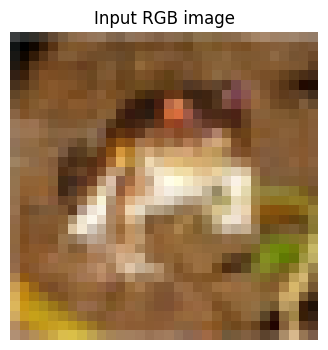


Input
Shape: (1, 3, 32, 32)
Number of elements: 3072
Data type: torch.float32
Min: -1.0
Max: 1.0
Mean: -0.18864886462688446
First 12 values: [-0.5372548699378967, -0.6627451181411743, -0.6078431010246277, -0.46666663885116577, -0.23137247562408447, -0.0666666030883789, 0.09019613265991211, 0.13725495338439941, 0.16862750053405762, 0.16862750053405762, 0.027451038360595703, -0.0196077823638916]

Conv1 output
Shape: (1, 6, 28, 28)
Number of elements: 4704
Data type: torch.float32
Min: -1.0670636892318726
Max: 0.9084895253181458
Mean: 0.1498977243900299
First 12 values: [-0.5138622522354126, -0.40922272205352783, -0.27123069763183594, -0.14239998161792755, -0.10293447971343994, -0.06814874708652496, -0.06222956255078316, -0.07732415944337845, -0.08755148947238922, -0.09052501618862152, -0.11901450157165527, -0.06512729823589325]


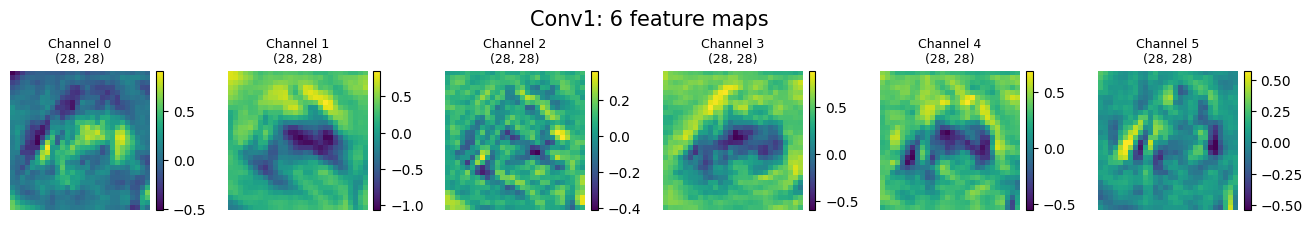


ReLU1 output
Shape: (1, 6, 28, 28)
Number of elements: 4704
Data type: torch.float32
Min: 0.0
Max: 0.9084895253181458
Mean: 0.19342650473117828
First 12 values: [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]


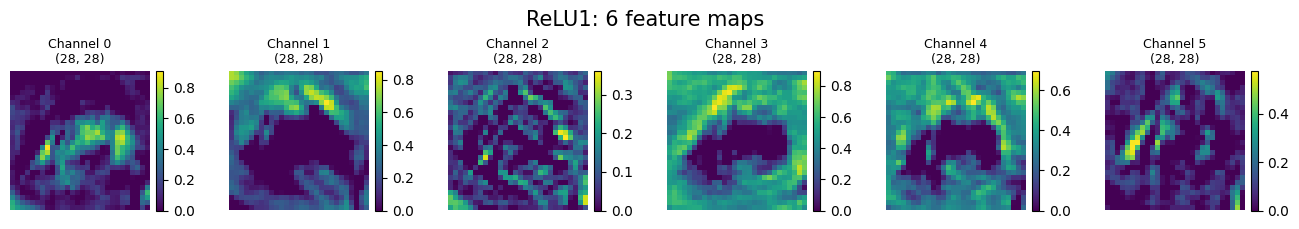


MaxPool1 output
Shape: (1, 6, 14, 14)
Number of elements: 1176
Data type: torch.float32
Min: 0.0
Max: 0.9084895253181458
Mean: 0.2557564377784729
First 12 values: [0.0, 0.0, 0.0, 0.0, 0.0, 0.024682067334651947, 0.09486619383096695, 0.007977068424224854, 0.009576070122420788, 0.047791488468647, 0.02883640117943287, 0.13511554896831512]


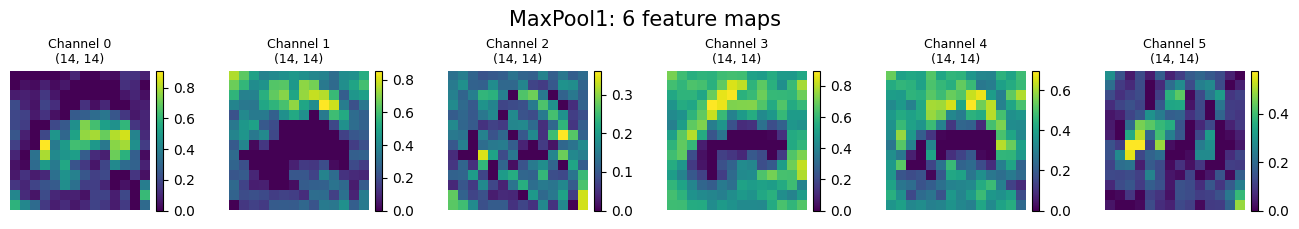


Conv2 output
Shape: (1, 16, 10, 10)
Number of elements: 1600
Data type: torch.float32
Min: -0.6212601661682129
Max: 0.44622936844825745
Mean: 0.012659561820328236
First 12 values: [-0.008563528768718243, 0.0005336053436622024, 0.06818685680627823, 0.13241389393806458, 0.13031181693077087, 0.05048887059092522, -0.013450375758111477, 0.056315530091524124, 0.04442068561911583, 0.05654622241854668, -0.009478126652538776, 0.013922031968832016]


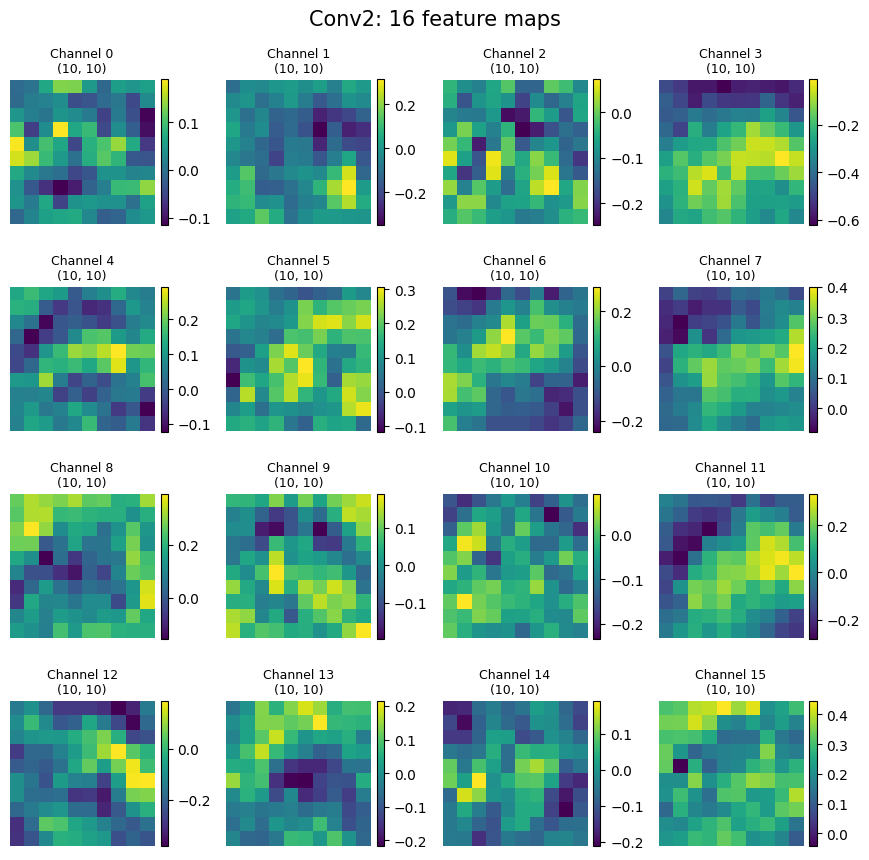


ReLU2 output
Shape: (1, 16, 10, 10)
Number of elements: 1600
Data type: torch.float32
Min: 0.0
Max: 0.44622936844825745
Mean: 0.06918850541114807
First 12 values: [0.0, 0.0005336053436622024, 0.06818685680627823, 0.13241389393806458, 0.13031181693077087, 0.05048887059092522, 0.0, 0.056315530091524124, 0.04442068561911583, 0.05654622241854668, 0.0, 0.013922031968832016]


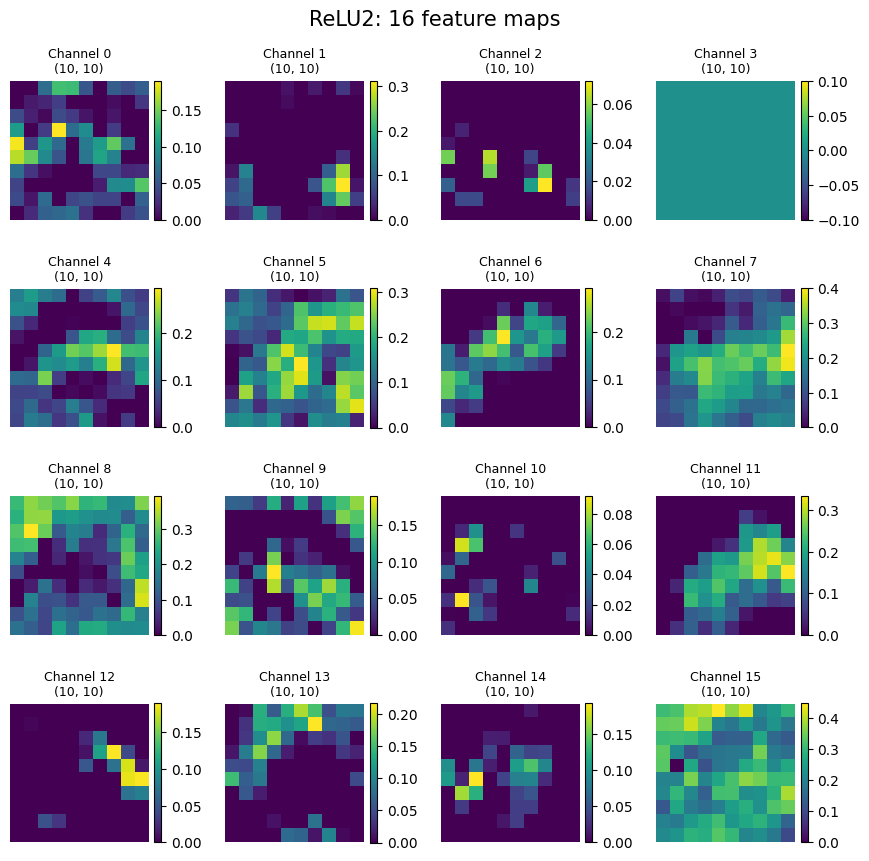


MaxPool2 output
Shape: (1, 16, 5, 5)
Number of elements: 400
Data type: torch.float32
Min: 0.0
Max: 0.44622936844825745
Mean: 0.10502222180366516
First 12 values: [0.013922031968832016, 0.13241389393806458, 0.13031181693077087, 0.056315530091524124, 0.05654622241854668, 0.10395701974630356, 0.18990729749202728, 0.09207647293806076, 0.03385205566883087, 0.0, 0.18725307285785675, 0.10015343874692917]


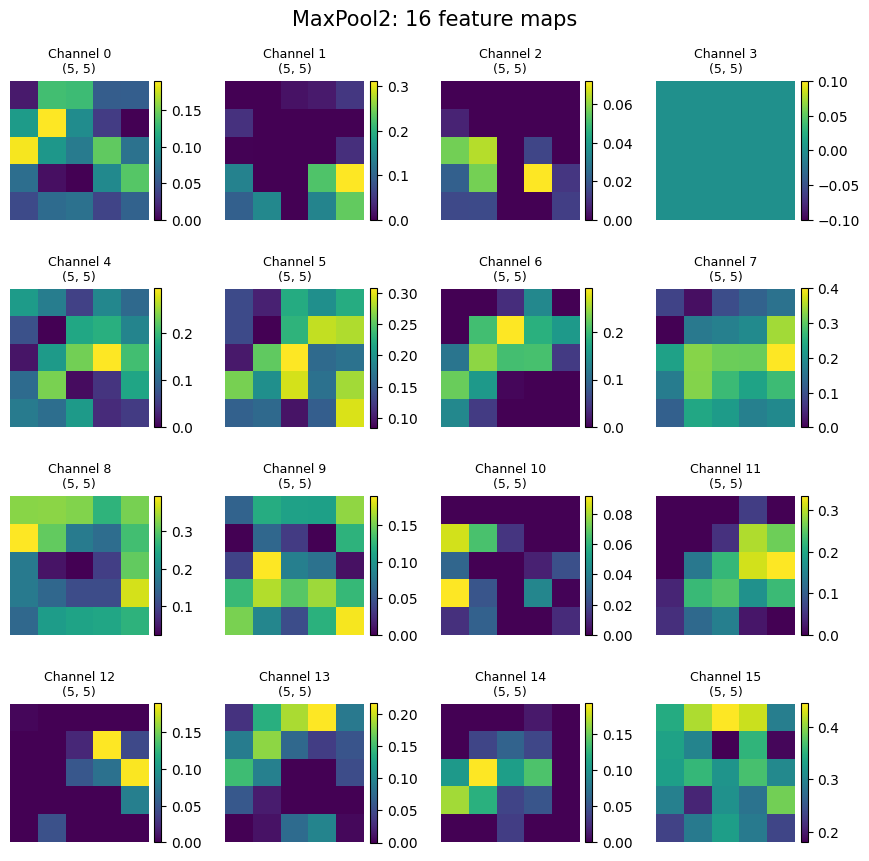


Flatten output
Shape: (1, 400)
Number of elements: 400
Data type: torch.float32
Min: 0.0
Max: 0.44622936844825745
Mean: 0.10502222180366516
Values:
 tensor([[0.0139, 0.1324, 0.1303, 0.0563, 0.0565, 0.1040, 0.1899, 0.0921, 0.0339,
         0.0000, 0.1873, 0.1002, 0.0790, 0.1434, 0.0714, 0.0688, 0.0074, 0.0000,
         0.0903, 0.1398, 0.0430, 0.0666, 0.0710, 0.0390, 0.0600, 0.0000, 0.0000,
         0.0152, 0.0227, 0.0512, 0.0443, 0.0000, 0.0000, 0.0000, 0.0000, 0.0018,
         0.0000, 0.0000, 0.0000, 0.0416, 0.1381, 0.0000, 0.0000, 0.2272, 0.3128,
         0.0956, 0.1461, 0.0000, 0.1410, 0.2371, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0071, 0.0000, 0.0000, 0.0000, 0.0000, 0.0565, 0.0639, 0.0000,
         0.0151, 0.0000, 0.0220, 0.0569, 0.0000, 0.0719, 0.0113, 0.0160, 0.0162,
         0.0000, 0.0000, 0.0135, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000,

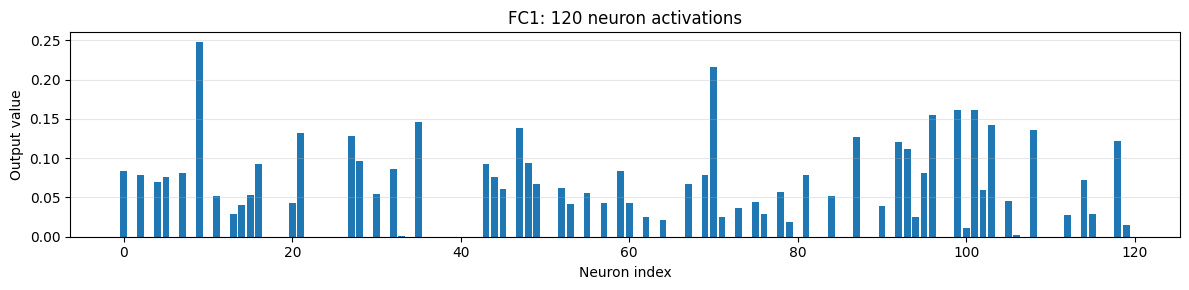


FC2 output before ReLU
Shape: (1, 84)
Number of elements: 84
Data type: torch.float32
Min: -0.1293954998254776
Max: 0.12313802540302277
Mean: -0.009502064436674118
Values:
 tensor([[-0.0925, -0.0191,  0.0819,  0.0486, -0.0558, -0.0698, -0.0502,  0.0693,
         -0.0039, -0.0381, -0.0600, -0.0830,  0.0088,  0.0320,  0.0055, -0.0685,
         -0.0336,  0.0634,  0.0129, -0.0619,  0.0334,  0.0701, -0.0269, -0.0766,
          0.0353, -0.1294, -0.0236,  0.0491, -0.0357, -0.0429, -0.0965, -0.0229,
         -0.0698, -0.1244,  0.0916,  0.0143,  0.0593, -0.0593, -0.0794,  0.0658,
          0.0308,  0.0335, -0.0398, -0.0666, -0.0255,  0.0113, -0.0160,  0.0451,
         -0.0896, -0.0593, -0.0213,  0.0413,  0.0552, -0.0356,  0.0134,  0.0047,
          0.0496, -0.0098,  0.0427,  0.0755, -0.0195, -0.0641, -0.0092,  0.0030,
         -0.0701,  0.1053, -0.1134,  0.0351,  0.0853, -0.0249, -0.0428, -0.0041,
          0.1231, -0.0728, -0.0522,  0.0770,  0.0383, -0.0095, -0.0062, -0.0154,
         -0.0988

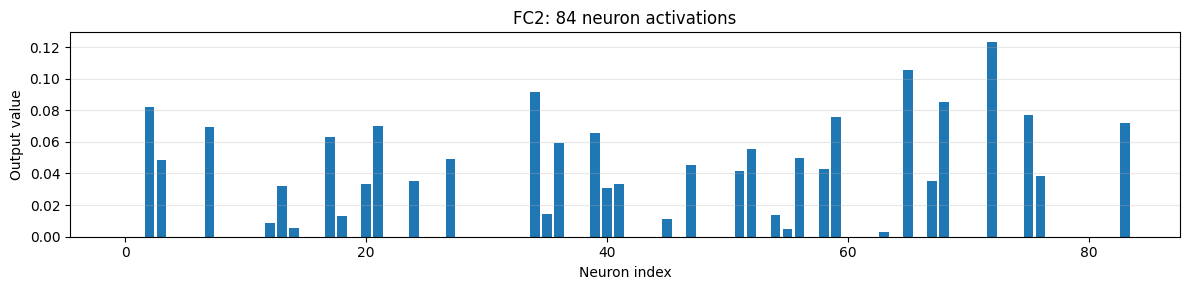


FC3 output (logits)
Shape: (1, 10)
Number of elements: 10
Data type: torch.float32
Min: -0.10743255913257599
Max: 0.09700185805559158
Mean: 0.026954496279358864
Values:
 tensor([[ 0.0475, -0.0263,  0.0541,  0.0339,  0.0970, -0.1028,  0.0922,  0.0937,
         -0.1074,  0.0876]])


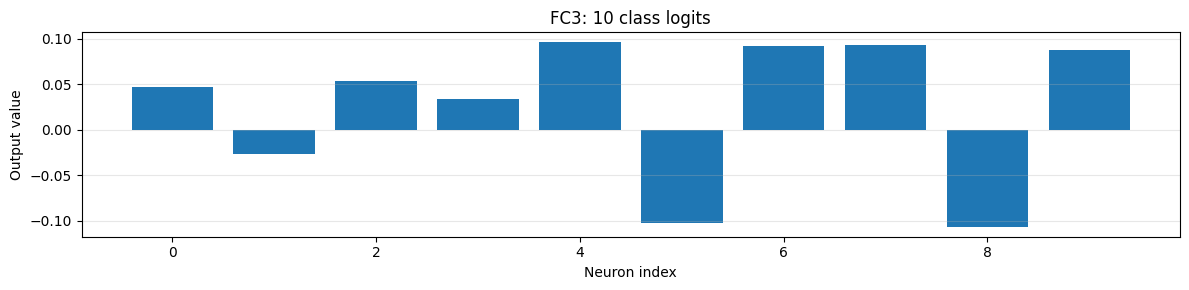


#################################################################
OUTPUT SHAPE SUMMARY
#################################################################
Conv1               : (1, 6, 28, 28)
ReLU1               : (1, 6, 28, 28)
MaxPool1            : (1, 6, 14, 14)
Conv2               : (1, 16, 10, 10)
ReLU2               : (1, 16, 10, 10)
MaxPool2            : (1, 16, 5, 5)
Flatten             : (1, 400)
FC1_before_ReLU     : (1, 120)
FC1                 : (1, 120)
FC2_before_ReLU     : (1, 84)
FC2                 : (1, 84)
FC3                 : (1, 10)


: 

In [ ]:
# Function to display feature maps
def show_feature_maps(tensor, title, cols=6):
    """
    Input tensor: [1, channels, height, width]
    Display each channel as an individual feature map.
    """

    tensor = tensor.detach().cpu()[0]

    num_maps = tensor.shape[0]
    rows = math.ceil(num_maps / cols)

    fig, axes = plt.subplots(
        rows,
        cols,
        figsize=(cols * 2.2, rows * 2.2),
        squeeze=False
    )

    fig.suptitle(title, fontsize=15)

    for i, ax in enumerate(axes.flat):

        if i < num_maps:
            feature_map = tensor[i].numpy()

            im = ax.imshow(feature_map, cmap="viridis")

            ax.set_title(
                f"Channel {i}\n{feature_map.shape}",
                fontsize=9
            )

            ax.axis("off")
            fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

        else:
            ax.axis("off")

    plt.tight_layout()
    plt.show()

# Function to display neuron activations
def show_neurons(tensor, title):
    """
    Input tensor: [1, number_of_neurons]
    """

    values = tensor.detach().cpu()[0].numpy()

    plt.figure(figsize=(12, 3))

    plt.bar(range(len(values)), values)

    plt.title(title)
    plt.xlabel("Neuron index")
    plt.ylabel("Output value")

    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

# Function to inspect tensor shape and values
def inspect_tensor(name, tensor, show_all=False):
    tensor = tensor.detach().cpu()

    print("\n" + "=" * 65)
    print(name)
    print("=" * 65)

    print("Shape:", tuple(tensor.shape))
    print("Number of elements:", tensor.numel())
    print("Data type:", tensor.dtype)

    print("Min:", tensor.min().item())
    print("Max:", tensor.max().item())
    print("Mean:", tensor.float().mean().item())

    if show_all:
        print("Values:\n", tensor)
    else:
        print("First 12 values:", tensor.flatten()[:12].tolist())

# Inspect weights, kernels and parameter counts
def inspect_parameters(model):

    print("\n" + "#" * 65)
    print("MODEL PARAMETERS")
    print("#" * 65)

    total_params = 0
    total_trainable = 0

    for name, module in model.named_children():

        params = sum(
            p.numel()
            for p in module.parameters(recurse=False)
        )

        trainable = sum(
            p.numel()
            for p in module.parameters(recurse=False)
            if p.requires_grad
        )

        total_params += params
        total_trainable += trainable

        print(f"\nLayer: {name}")
        print("Parameter count:", params)
        print("Trainable parameters:", trainable)

        if isinstance(module, nn.Conv2d):

            print("Weight shape:", tuple(module.weight.shape))
            print("Bias shape:", tuple(module.bias.shape))

            print("Kernel weights:")
            print(module.weight.detach().cpu())

            print("Bias:")
            print(module.bias.detach().cpu())

        elif isinstance(module, nn.Linear):

            print("Weight shape:", tuple(module.weight.shape))
            print("Bias shape:", tuple(module.bias.shape))

            print("Weight matrix (first 3 rows, 8 columns):")
            print(module.weight[:3, :8].detach().cpu())

            print("Bias values:")
            print(module.bias.detach().cpu())

    print("\n" + "-" * 65)
    print("Total parameters:", total_params)
    print("Total trainable parameters:", total_trainable)

# Forward pass: collect every intermediate output
def visualize_cnn(model, image):

    model.eval()

    if image.ndim == 3:
        image = image.unsqueeze(0)

    print("\nInput image shape:", tuple(image.shape))

    # Store intermediate tensors for inspection
    activations = {}

    with torch.no_grad():

        # ---------------- Input ----------------
        x = image

        # Display RGB image.
        # Inverse normalization: mean=0.5, std=0.5
        rgb = x[0].detach().cpu() * 0.5 + 0.5
        rgb = rgb.permute(1, 2, 0).clamp(0, 1).numpy()

        plt.figure(figsize=(4, 4))
        plt.imshow(rgb)
        plt.title("Input RGB image")
        plt.axis("off")
        plt.show()

        inspect_tensor("Input", x)

        # ---------------- Conv1 ----------------
        conv1_out = model.conv1(x)
        activations["Conv1"] = conv1_out

        inspect_tensor("Conv1 output", conv1_out)
        show_feature_maps(conv1_out, "Conv1: 6 feature maps")

        # ---------------- ReLU1 ----------------
        relu1_out = F.relu(conv1_out)
        activations["ReLU1"] = relu1_out

        inspect_tensor("ReLU1 output", relu1_out)
        show_feature_maps(relu1_out, "ReLU1: 6 feature maps")

        # ---------------- MaxPool1 ----------------
        pool1_out = model.pool(relu1_out)
        activations["MaxPool1"] = pool1_out

        inspect_tensor("MaxPool1 output", pool1_out)
        show_feature_maps(pool1_out, "MaxPool1: 6 feature maps")

        # ---------------- Conv2 ----------------
        conv2_out = model.conv2(pool1_out)
        activations["Conv2"] = conv2_out

        inspect_tensor("Conv2 output", conv2_out)
        show_feature_maps(
            conv2_out,
            "Conv2: 16 feature maps",
            cols=4
        )

        # ---------------- ReLU2 ----------------
        relu2_out = F.relu(conv2_out)
        activations["ReLU2"] = relu2_out

        inspect_tensor("ReLU2 output", relu2_out)
        show_feature_maps(
            relu2_out,
            "ReLU2: 16 feature maps",
            cols=4
        )

        # ---------------- MaxPool2 ----------------
        pool2_out = model.pool(relu2_out)
        activations["MaxPool2"] = pool2_out

        inspect_tensor("MaxPool2 output", pool2_out)
        show_feature_maps(
            pool2_out,
            "MaxPool2: 16 feature maps",
            cols=4
        )

        # ---------------- Flatten ----------------
        flat_out = torch.flatten(pool2_out, 1)
        activations["Flatten"] = flat_out

        inspect_tensor("Flatten output", flat_out, show_all=True)

        # ---------------- FC1 ----------------
        fc1_pre = model.fc1(flat_out)
        fc1_out = F.relu(fc1_pre)

        activations["FC1_before_ReLU"] = fc1_pre
        activations["FC1"] = fc1_out

        inspect_tensor(
            "FC1 output before ReLU",
            fc1_pre,
            show_all=True
        )

        inspect_tensor(
            "FC1 output after ReLU",
            fc1_out,
            show_all=True
        )

        show_neurons(fc1_out, "FC1: 120 neuron activations")

        # ---------------- FC2 ----------------
        fc2_pre = model.fc2(fc1_out)
        fc2_out = F.relu(fc2_pre)

        activations["FC2_before_ReLU"] = fc2_pre
        activations["FC2"] = fc2_out

        inspect_tensor(
            "FC2 output before ReLU",
            fc2_pre,
            show_all=True
        )

        inspect_tensor(
            "FC2 output after ReLU",
            fc2_out,
            show_all=True
        )

        show_neurons(fc2_out, "FC2: 84 neuron activations")

        # ---------------- FC3 ----------------
        fc3_out = model.fc3(fc2_out)
        activations["FC3"] = fc3_out

        inspect_tensor(
            "FC3 output (logits)",
            fc3_out,
            show_all=True
        )

        show_neurons(fc3_out, "FC3: 10 class logits")

    print("\n" + "#" * 65)
    print("OUTPUT SHAPE SUMMARY")
    print("#" * 65)

    for name, tensor in activations.items():
        print(f"{name:20s}: {tuple(tensor.shape)}")

    return activations

# Load one CIFAR-10 image and run inspection
torch.manual_seed(42)

image, label = trainset[0]

print("Ground-truth class index:", label)

# Batch size = 1
image = image.unsqueeze(0)

# Create a fresh model using the original architecture
model = Net()

# Inspect kernel matrices and weights
inspect_parameters(model)

# Visualize all layers
activations = visualize_cnn(model, image)